# Lipa Mdogo Mdogo: BNPL Default Risk Prediction
### Credit Risk Prediction and Decision-Support Model | Mkopo Insights (Capstone Group 3)

**Methodology:** CRISP-DM (Business Understanding, Data Understanding, Data Preparation, Modelling, Evaluation, Deployment)

**Tools:** Python, pandas, NumPy, scikit-learn, Matplotlib, Seaborn, joblib, Streamlit, GitHub

**Dataset:** Kaggle, *Buy Now Pay Later (BNPL) Default Risk* (Indian e-commerce, 10,000 customers, 11 columns, CC0). Loaded from `BNPL_Financial_Default_Risk_Dataset.csv`.

**Target:** `Default_Risk` (Low, Medium, High)

**Currency and period:** all money fields are converted from USD to Kenya shillings (KES) at a fixed reference rate of **1 USD = KES 129.89** (CBK indicative rate, 26 October 2026). Annual income is divided by **12** to give **monthly income**, the basis on which Kenyan lenders assess affordability.

| Role | Assignee |
|---|---|
| Business analyst | Faith |
| Data analyst | Benedict and George |
| Data scientist | George |
| Quality assurance | Benedict |
| Project lead | Kelvin |
| Business reviewers | Francis and Barbara |

**Notebook map**
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modelling
5. Evaluation 
6. Deployment 
7. Recommendations, Limitations and Monitoring


# 1. Business Understanding

## 1.1 Background
Buy Now, Pay Later (BNPL), known locally as *Lipa Mdogo Mdogo*, lets customers acquire goods immediately and repay in instalments. It increases sales for merchants and revenue for providers, but late or missed repayments expose providers to credit risk, collection costs and portfolio deterioration.

## 1.2 Problem Statement
BNPL providers need an effective way to assess customer credit risk before extending credit and to monitor risk during repayment. Where existing methods do not separate customers with different risk profiles, providers either take avoidable losses or unnecessarily restrict credit to customers who can repay.

This project investigates whether customer demographic, financial and shopping-behaviour data can predict a customer's default risk category (Low, Medium, High) and generate useful decision-support insights.

## 1.3 Main Objective
To develop and evaluate a machine learning model that identifies customers at risk of default on BNPL obligations and to package it as an interactive decision-support application.

## 1.4 Specific Objectives
1. **Default risk prediction:** analyse demographics, income, credit score, existing BNPL exposure, repayment history and shopping behaviour to identify patterns associated with default.
2. **Customer segmentation:** compare risk across segments (Students, Employed, Freelancers, Unemployed, age bands, shopping categories).
3. **Decision support:** show how predicted risk could support credit assessment, responsible credit limits, early-warning monitoring and risk management.

## 1.5 Stakeholders and the Decisions Supported
| Stakeholder | Decision supported |
|---|---|
| Credit analysts | Approve, refer for review, or decline a BNPL application |
| Risk managers | Set credit limits by risk band; monitor portfolio mix |
| Collections teams | Prioritise early-warning contact for High-risk accounts |
| Business managers | Balance approval rates against expected losses |


# 2. Data Understanding
## 2.1 Setup

In [3]:
# Import libraries for data analysis, visualisation, and machine learning

import os
import glob
import json
import warnings
import urllib.request
import zipfile
from datetime import datetime


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# # Data preprocessing and model validation
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import (
#     OneHotEncoder, StandardScaler, FunctionTransformer
# )
# from sklearn.impute import SimpleImputer

# # Machine learning models
# from sklearn.dummy import DummyClassifier
# from sklearn.linear_model import LogisticRegression
# from sklearn.tree import DecisionTreeClassifier, plot_tree
# from sklearn.ensemble import RandomForestClassifier

# # Model evaluation
# from sklearn.metrics import (
#     accuracy_score, f1_score, precision_score, recall_score,
#     classification_report, confusion_matrix, ConfusionMatrixDisplay,
#     roc_auc_score, roc_curve, brier_score_loss
# )
# from sklearn.calibration import calibration_curve
# from sklearn.inspection import permutation_importance

# Model saving and version information
# import joblib
# import sklearn

# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Risk categories and chart colours
CLASS_ORDER = ["Low", "Medium", "High"]
RISK_COLORS = {
    "Low": "#8FB3DE",
    "Medium": "#3E6FB0",
    "High": "#0B2545"
}
NAVY = "#0B2545"

# Visualisation settings
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# Create output folders
for folder in ["figures", "models", "reports"]:
    os.makedirs(folder, exist_ok=True)

## 2.2 Load the Data
The BNPL dataset is available in Excel (`BNPL.xlsx`) or CSV (`BNPL_Financial_Default_Risk_Dataset.csv`) format, sourced from Kaggle.

The code locates and loads the available file. The original dataset is stored as `df_raw`, while a separate working copy (`df`) is created for data cleaning and analysis, preserving the original data.

In [4]:
# Download BNPL dataset directly from Kaggle (no Kaggle API installation)
url = "https://www.kaggle.com/api/v1/datasets/download/itzzomkar/buy-now-pay-later-bnpl-default-risk"

zip_path = "BNPL_dataset.zip"

urllib.request.urlretrieve(url, zip_path)

# Extract downloaded dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(".")

os.remove(zip_path)

candidates = ["BNPL.xlsx", "data/BNPL.xlsx",
              "BNPL_Financial_Default_Risk_Dataset.csv", "data/BNPL_Financial_Default_Risk_Dataset.csv"]
candidates += glob.glob("*BNPL*.csv") + glob.glob("*BNPL*.xlsx")
DATA_PATH = next((p for p in candidates if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place BNPL.xlsx or the Kaggle BNPL csv beside this notebook (or in data/).")

df_raw = pd.read_excel(DATA_PATH) if DATA_PATH.endswith(".xlsx") else pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()
df = df_raw.copy()                         # df_raw stays unchanged for audit
print(f"Loaded {DATA_PATH}: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded BNPL_Financial_Default_Risk_Dataset.csv: 10,000 rows x 11 columns


,Customer_ID,Age,Employment_Status,Income_USD,Credit_Score,Total_BNPL_Active_Loans,Total_BNPL_Debt_USD,Late_Payment_History,Shopping_Category_Most_Frequent,Average_Transaction_Value_USD,Default_Risk
0,C00001,29,Employed,"73,405.000",637.000,2,193,No,Fashion,118,Low
1,C00002,64,Employed,"53,732.000",815.000,0,0,No,Electronics,662,Low
2,C00003,26,Freelancer,"69,930.000",723.000,2,273,No,Fashion,76,Low
3,C00004,19,Employed,"96,941.000",716.000,3,421,No,Home/Furniture,449,Low
4,C00005,55,Student,"15,959.000",675.000,2,145,No,Travel,974,Low


## 2.3 Data Dictionary 
This step checks whether the BNPL dataset contains all 11 expected columns as defined in the data dictionary.

 
| Column | Type | Description |
|---|---|---|
| `Customer_ID` | Identifier | Unique customer key  |
| `Age` | Numeric | Age in years |
| `Employment_Status` | Categorical | Employed, Student, Freelancer, Unemployed |
| `Income_USD` | Numeric | Annual income in USD (becomes `Monthly_Income_KES`) |
| `Credit_Score` | Numeric | Score on a 300 to 900 scale |
| `Total_BNPL_Active_Loans` | Numeric | Number of active BNPL loans |
| `Total_BNPL_Debt_USD` | Numeric | Total outstanding BNPL debt in USD (becomes `Total_BNPL_Debt_KES`) |
| `Late_Payment_History` | Binary | Whether the customer has paid late before |
| `Shopping_Category_Most_Frequent` | Categorical | Most frequent shopping category |
| `Average_Transaction_Value_USD` | Numeric | Average BNPL transaction value in USD (becomes `Average_Transaction_Value_KES`) |
| `Default_Risk` | **Target** | Low, Medium, High |

In [5]:
TARGET = "Default_Risk"
ID_COL = "Customer_ID"
EXPECTED = ["Customer_ID", "Age", "Employment_Status", "Income_USD", "Credit_Score",
            "Total_BNPL_Active_Loans", "Total_BNPL_Debt_USD", "Late_Payment_History",
            "Shopping_Category_Most_Frequent", "Average_Transaction_Value_USD", "Default_Risk"]

missing_cols = set(EXPECTED) - set(df.columns)
extra_cols = set(df.columns) - set(EXPECTED)
print("Columns missing vs data dictionary:", missing_cols or "none")
print("Columns not in data dictionary   :", extra_cols or "none")
df.info()

Columns missing vs data dictionary: none
Columns not in data dictionary   : none
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Customer_ID                      10000 non-null  str    
 1   Age                              10000 non-null  int64  
 2   Employment_Status                10000 non-null  str    
 3   Income_USD                       9695 non-null   float64
 4   Credit_Score                     9702 non-null   float64
 5   Total_BNPL_Active_Loans          10000 non-null  int64  
 6   Total_BNPL_Debt_USD              10000 non-null  int64  
 7   Late_Payment_History             10000 non-null  str    
 8   Shopping_Category_Most_Frequent  10000 non-null  str    
 9   Average_Transaction_Value_USD    10000 non-null  int64  
 10  Default_Risk                     10000 non-null  str    
dtypes: float64(

## 2.4 Kenya Localisation: USD to KES and Monthly Normalisation
Kenyan lenders, the app's users and the business reviewers think in shillings and in monthly income (payslips, M-Pesa statements and CRB affordability checks are all monthly).

| Source column | Treatment | New column |
|---|---|---|
| `Income_USD` (annual) | x 129.89, then / 12 | `Monthly_Income_KES` |
| `Total_BNPL_Debt_USD` (balance outstanding) | x 129.89 | `Total_BNPL_Debt_KES` |
| `Average_Transaction_Value_USD` (per purchase) | x 129.89 | `Average_Transaction_Value_KES` |

**Exchange Rate:** All monetary values are converted from USD to Kenya shillings (KES) using a fixed rate of 1 USD = KES 129.89, based on the CBK indicative rate for 26 October 2026 (https://www.centralbank.go.ke/forex/).

**Monthly Income:** Annual income is divided by 12 to obtain monthly income, making it easier to assess customer affordability.

**Other Monetary Values:** BNPL debt and average transaction value are converted to KES but are not divided by 12 because they are not annual amounts.

**Data Limitation:** The dataset represents Indian e-commerce customers. Converting the values to KES makes the analysis easier to interpret in a Kenyan context but does not change the customers' actual financial circumstances

In [6]:
USD_TO_KES = 129.89            # CBK indicative rate on 26 Oct 2026
MONTHS_PER_YEAR = 12

CONVERSIONS = {               
    "Income_USD": ("Monthly_Income_KES", True),
    "Total_BNPL_Debt_USD": ("Total_BNPL_Debt_KES", False),
    "Average_Transaction_Value_USD": ("Average_Transaction_Value_KES", False),
}
ANNUAL_TO_MONTHLY = [src for src, (_, monthly) in CONVERSIONS.items() if monthly]

def localise_to_kenya(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    for src, (new, monthly) in CONVERSIONS.items():
        if src in out.columns:
            values = pd.to_numeric(out[src], errors="coerce") * USD_TO_KES
            if monthly:
                values = values / MONTHS_PER_YEAR
            out[new] = values.round(2)
            out = out.drop(columns=src)
    return out

df = localise_to_kenya(df)

# Reconciliation: one customer before and after, and totals that must agree
check = pd.DataFrame({
    "USD (source)": [df_raw.loc[0, s] for s in CONVERSIONS],
    "KES (converted)": [df.loc[0, n] for n, _ in CONVERSIONS.values()],
}, index=[f"{s} -> {n}" for s, (n, _) in CONVERSIONS.items()])
display(check)

for src, (new, monthly) in CONVERSIONS.items():
    expected = df_raw[src].sum() * USD_TO_KES / (MONTHS_PER_YEAR if monthly else 1)
    assert np.isclose(df[new].sum(), expected, rtol=1e-4), f"Conversion mismatch on {src}"
print(f"Rate 1 USD = KES {USD_TO_KES}; divided by {MONTHS_PER_YEAR}: {ANNUAL_TO_MONTHLY}. Totals reconcile.")
df[[n for n, _ in CONVERSIONS.values()]].describe().T

,USD (source),KES (converted)
Income_USD -> Monthly_Income_KES,"73,405.000","794,547.950"
Total_BNPL_Debt_USD -> Total_BNPL_Debt_KES,193.000,"25,068.770"
Average_Transaction_Value_USD -> Average_Transaction_Value_KES,118.000,"15,327.020"


Rate 1 USD = KES 129.89; divided by 12: ['Income_USD']. Totals reconcile.


,count,mean,std,min,25%,50%,75%,max
Monthly_Income_KES,"9,695.000","584,300.885","322,531.742","54,120.830","238,093.785","634,252.870","834,256.410","1,509,451.690"
Total_BNPL_Debt_KES,"10,000.000","45,306.294","40,927.852",0.000,"18,444.380","34,096.125","60,658.630","354,729.590"
Average_Transaction_Value_KES,"10,000.000","43,098.502","34,337.801","1,298.900","12,729.220","38,252.605","66,893.350","184,443.800"


## 2.5 Data Quality Assessment

Before cleaning the dataset, we assess its quality by checking missing values, duplicate records, data types, unusual values and possible outliers. This helps identify issues that may affect analysis and machine learning models.


In [7]:
# Missing Values and Duplicates

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
print(f"Fully duplicated rows : {df.duplicated().sum()}")
if ID_COL in df:
    print(f"Duplicated Customer_ID: {df[ID_COL].duplicated().sum()}")
quality

Fully duplicated rows : 0
Duplicated Customer_ID: 0


,dtype,non_null,missing,missing_%,unique
Customer_ID,str,10000,0,0.000,10000
Age,int64,10000,0,0.000,47
Employment_Status,str,10000,0,0.000,4
Credit_Score,float64,9702,298,2.980,457
Total_BNPL_Active_Loans,int64,10000,0,0.000,11
Late_Payment_History,str,10000,0,0.000,2
Shopping_Category_Most_Frequent,str,10000,0,0.000,5
Default_Risk,str,10000,0,0.000,3
Monthly_Income_KES,float64,9695,305,3.050,9003
Total_BNPL_Debt_KES,float64,10000,0,0.000,1288


The dataset contains **no duplicate records or duplicate Customer IDs**, indicating that each customer is uniquely represented.

Only two variables have missing values:
- **Credit Score:** 298 records (2.98%).
- **Monthly Income:** 305 records (3.05%).

All other variables, including the target variable (`Default_Risk`), have complete information.

The dataset is largely complete. The missing values will be addressed during data preparation.

In [8]:
# Check for Categorical data quality
for col in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]:
    if col == ID_COL:
        continue
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).to_string())


Employment_Status:
Employment_Status
Employed      6029
Student       1968
Freelancer    1495
Unemployed     508

Late_Payment_History:
Late_Payment_History
No     7524
Yes    2476

Shopping_Category_Most_Frequent:
Shopping_Category_Most_Frequent
Fashion                 4012
Electronics             2991
Home/Furniture          1512
Travel                   971
Groceries/Essentials     514

Default_Risk:
Default_Risk
Low       8801
Medium     678
High       521


### Interpretation of Categorical Data Quality Results

The analysis examined four categorical variables and the findings are:

- Most customers are employed.
- Most customers have no history of late payments, while approximately one in four have previously paid late.
- Fashion and Electronics are the most popular shopping categories.
- Most customers are classified as Low risk. This shows that the target variable is highly imbalanced, which will need attention during modelling.

However, the large difference between the risk categories is an important finding. We will need to consider this imbalance when developing and evaluating our default risk prediction model.

In [9]:
# Numerical variables to understand customer characteristics
num_raw = df.select_dtypes(include=np.number).columns.tolist()
display(df[num_raw].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)

checks = {
    "Age < 18 or > 100": ((df["Age"] < 18) | (df["Age"] > 100)).sum() if "Age" in df else None,
    "Credit_Score outside 300-900": ((df["Credit_Score"] < 300) | (df["Credit_Score"] > 900)).sum() if "Credit_Score" in df else None,
    "Income zero or negative": (df["Monthly_Income_KES"] <= 0).sum(),
    "Negative BNPL debt": (df["Total_BNPL_Debt_KES"] < 0).sum(),
    "Debt > 0 but 0 active loans": ((df["Total_BNPL_Debt_KES"] > 0) & (df["Total_BNPL_Active_Loans"] == 0)).sum(),
    "Active loans > 0 but zero debt": ((df["Total_BNPL_Debt_KES"] == 0) & (df["Total_BNPL_Active_Loans"] > 0)).sum(),
}
pd.Series(checks, name="records flagged").to_frame()

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Age,"10,000.000",34.248,12.911,18.000,18.000,19.000,23.000,31.000,43.000,59.000,64.000,64.000
Credit_Score,"9,702.000",663.671,76.222,300.000,449.000,523.000,620.000,673.000,717.000,771.000,810.000,850.000
Total_BNPL_Active_Loans,"10,000.000",2.317,1.854,0.000,0.000,0.000,1.000,2.000,3.000,6.000,9.000,10.000
Monthly_Income_KES,"9,695.000","584,300.885","322,531.742","54,120.830","54,120.830","94,027.370","238,093.785","634,252.870","834,256.410","1,072,683.579","1,223,279.995","1,509,451.690"
Total_BNPL_Debt_KES,"10,000.000","45,306.294","40,927.852",0.000,0.000,0.000,"18,444.380","34,096.125","60,658.630","127,811.760","192,498.279","354,729.590"
Average_Transaction_Value_KES,"10,000.000","43,098.502","34,337.801","1,298.900","2,078.240","5,585.270","12,729.220","38,252.605","66,893.350","106,646.184","138,595.228","184,443.800"


,records flagged
Age < 18 or > 100,0
Credit_Score outside 300-900,0
Income zero or negative,0
Negative BNPL debt,0
Debt > 0 but 0 active loans,0
Active loans > 0 but zero debt,16


Most numerical values pass the basic validity checks, with no unrealistic ages, credit scores outside the selected range, negative incomes or negative debts.

The main issue identified is the 16 customers with active loans but no outstanding debt. These records will be reviewed during data preparation before deciding whether any correction is necessary.

In [10]:
# Check numerical columns for unusually high or low values using the IQR method
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: iqr_outliers(df[c].dropna()) for c in num_raw}, name="IQR outliers").to_frame()

,IQR outliers
Age,0
Credit_Score,182
Total_BNPL_Active_Loans,398
Monthly_Income_KES,0
Total_BNPL_Debt_KES,536
Average_Transaction_Value_KES,49


The results show:

- **Age:** No outliers were detected.
- **Credit Score:** 182 outliers (1.82% of all records).
- **Active BNPL Loans:** 398 outliers (3.98%).
- **Monthly Income:** No outliers were detected.
- **Total BNPL Debt:** 536 outliers (5.36%).
- **Average Transaction Value:** 49 outliers (0.49%).

BNPL debt has the highest number of outliers, followed by active BNPL loans and credit scores. This suggests that some customers have borrowing patterns or credit scores that differ significantly from most customers.

However, outliers do not necessarily mean the data is incorrect. They may represent genuine customer financial behaviour and could be useful in predicting default risk.

The identified outliers will be examined further during data preparation. We will not automatically remove them because they may contain important information about customers at risk of default.

In [11]:
# Relationship Between Missing Values and Default Risk

miss_rows = []
for col in [c for c in df.columns if df[c].isna().any()]:
    flag = df[col].isna().map({True: "Missing", False: "Present"})
    ct = pd.crosstab(flag, df[TARGET])[CLASS_ORDER]
    p = stats.chi2_contingency(ct)[1]
    share = pd.crosstab(flag, df[TARGET], normalize="index")[CLASS_ORDER] * 100
    for status, r in share.iterrows():
        miss_rows.append({"column": col, "status": status, "n": int(ct.loc[status].sum()),
                          **{f"{k}_%": r[k] for k in CLASS_ORDER}, "chi2_p_value": p})
missing_vs_target = pd.DataFrame(miss_rows).round(3)
missing_vs_target

,column,status,n,Low_%,Medium_%,High_%,chi2_p_value
0,Credit_Score,Missing,298,87.919,8.054,4.027,0.458
1,Credit_Score,Present,9702,88.013,6.741,5.246,0.458
2,Monthly_Income_KES,Missing,305,88.525,6.557,4.918,0.959
3,Monthly_Income_KES,Present,9695,87.994,6.787,5.219,0.959


- This analysis examines whether missing values in the dataset are associated with customers' default risk levels (Low, Medium, or High). 
- The code compares customers with missing information against those with complete information and calculates the percentage of customers in each risk category.
- A Chi-square test is used to determine whether missing values are significantly associated with default risk.
- A p-value below 0.05 indicates a statistically significant relationship, while a p-value above 0.05 indicates insufficient evidence of a relationship.

    **Our Results:**
  -  Credit Score (p = 0.458): No statistically significant relationship between missing credit scores and default risk.
  - Monthly Income (p = 0.959): No statistically significant relationship between missing income values and default risk.

 Both p-values are above 0.05, suggesting that missing values are not significantly associated with default risk.

## 2.6 Target Distribution
This is to understand how many customers fall into each risk category and determine whether the dataset is balanced or imbalanced.

,count,%
Default_Risk,,
Low,8801,88.000
Medium,678,6.800
High,521,5.200


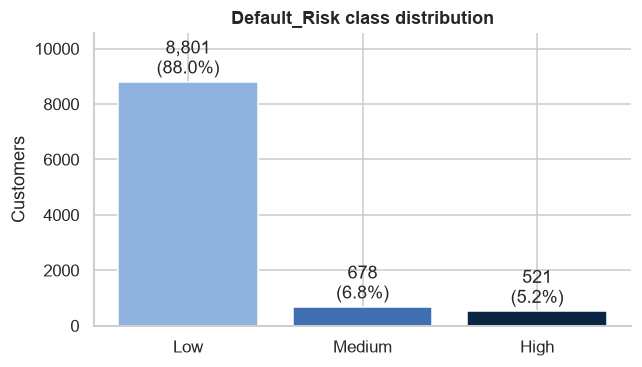

Majority:minority ratio = 16.89


In [12]:
# Calculate class counts and percentages and visualise the distribution
# Assess class imbalance using the majority-to-minority ratio.

target_counts = df[TARGET].value_counts().reindex(CLASS_ORDER)
target_pct = (target_counts / target_counts.sum() * 100).round(1)
display(pd.DataFrame({"count": target_counts, "%": target_pct}))

# Visualise the distribution of customers across risk categories
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(CLASS_ORDER, target_counts.values, color=[RISK_COLORS[c] for c in CLASS_ORDER])
ax.bar_label(bars, labels=[f"{n:,}\n({p}%)" for n, p in zip(target_counts, target_pct)], padding=2)
ax.set_title("Default_Risk class distribution"); ax.set_ylabel("Customers")
ax.set_ylim(0, target_counts.max() * 1.2)
plt.tight_layout(); plt.savefig("figures/01_target_distribution.png"); plt.show()

imbalance_ratio = target_counts.max() / target_counts.min()
print(f"Majority:minority ratio = {imbalance_ratio:.2f}")

**Interpretation**

The dataset is highly imbalanced, with 88% Low Risk, 6.8% Medium Risk, and 5.2% High Risk customers. This may cause the model to favour the Low Risk category. Techniques such as class weightiTE may help address this imbalance during model training.

## 2.7 Analysis of Individual Customer Characteristics

- It examines each variable individually to understand its distribution, patterns, and characteristics.
- It helps identify unusual values, skewness, and potential outliers before building the machine learning model.

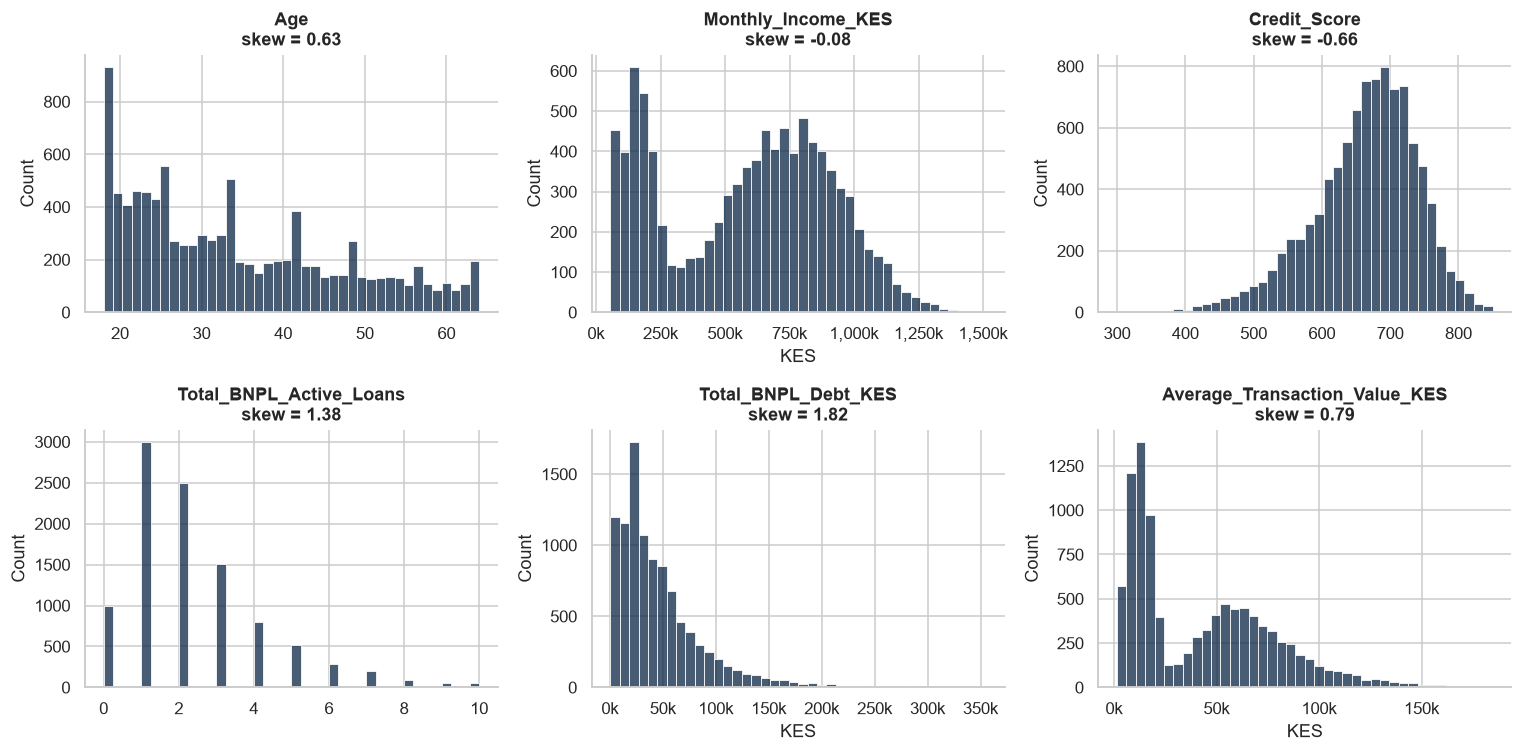

In [13]:
#  Examine numerical distributions, skewness, and potential outliers

NUM_COLS = [c for c in ["Age", "Monthly_Income_KES", "Credit_Score", "Total_BNPL_Active_Loans",
                        "Total_BNPL_Debt_KES", "Average_Transaction_Value_KES"] if c in df]
MONEY_COLS = ["Monthly_Income_KES", "Total_BNPL_Debt_KES", "Average_Transaction_Value_KES"]
CAT_COLS = [c for c in ["Employment_Status", "Late_Payment_History",
                        "Shopping_Category_Most_Frequent"] if c in df]

# Visualise numerical distributions using histograms

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, NUM_COLS):
    sns.histplot(df[col].dropna(), bins=40, color=NAVY, ax=ax)
    ax.set_title(f"{col}\nskew = {df[col].skew():.2f}"); ax.set_xlabel("KES" if col in MONEY_COLS else "")
    if col in MONEY_COLS:
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
plt.tight_layout(); plt.savefig("figures/02_numeric_distributions.png"); plt.show()

**Interpretation**
- Age (0.63): Moderately right-skewed, indicating more younger customers than older customers.
- Monthly Income (-0.08): Nearly symmetrical, with no significant skewness.
- Credit Score (-0.66): Moderately left-skewed, with most customers having relatively higher credit scores.
- Active BNPL Loans (1.38): Highly right-skewed, with most customers holding fewer active loans.
- Total BNPL Debt (1.82): Highly right-skewed, indicating most customers have lower debt balances, while a few have substantially higher debt.
- Average Transaction Value (0.79): Moderately right-skewed, with most transactions concentrated at lower values.

BNPL debt and active loans show the strongest positive skewness, suggesting potential outliers. These variables may benefit from transformation or further investigation before model training.


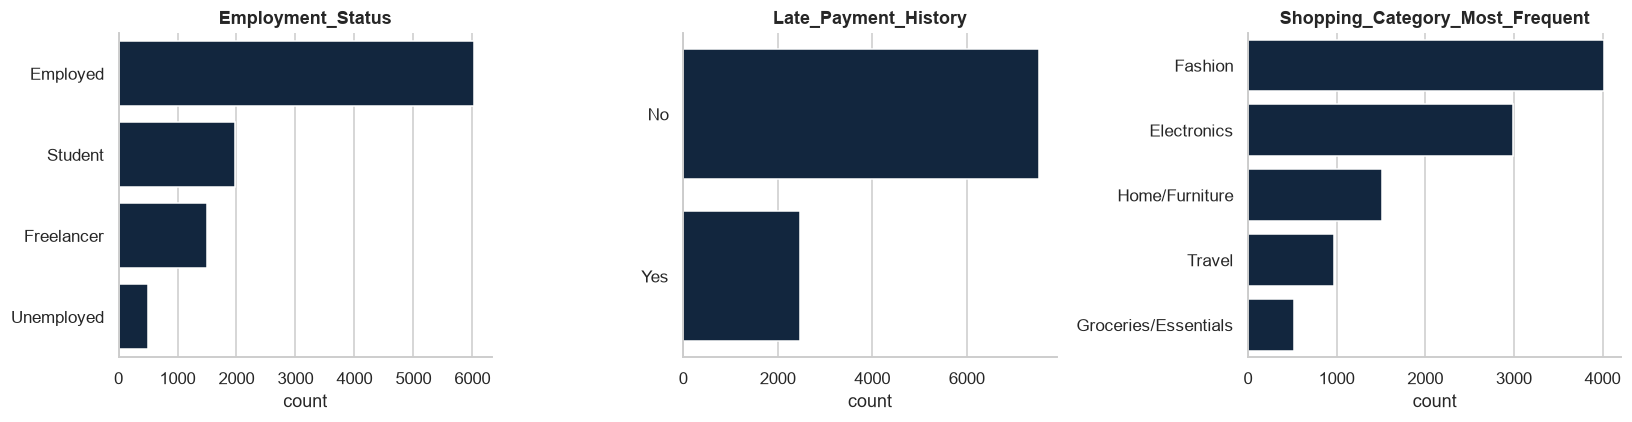

In [14]:
# Visualise the frequency of each category to identify common patterns and imbalances.

fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(5 * len(CAT_COLS), 4))
for ax, col in zip(np.atleast_1d(axes), CAT_COLS):
    order = df[col].value_counts().index
    sns.countplot(y=df[col].astype(str), order=order.astype(str), color=NAVY, ax=ax)
    ax.set_title(col); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("figures/03_categorical_counts.png"); plt.show()

**Interpretation**
- Employment Status: Most customers are employed, followed by students and freelancers, while unemployed customers form the smallest group.
- Late Payment History: The majority of customers have no history of late payments, suggesting generally positive repayment behaviour.
- Shopping Category: Fashion is the most popular category, followed by electronics, while groceries and essentials are the least common.

The categorical variables show uneven distributions, with employed customers, those without late payment history, and fashion shoppers dominating their respective categories. These patterns provide insights into customer characteristics and shopping behaviour.

## 2.8 Relationship Between Customer Characteristics and Default Risk

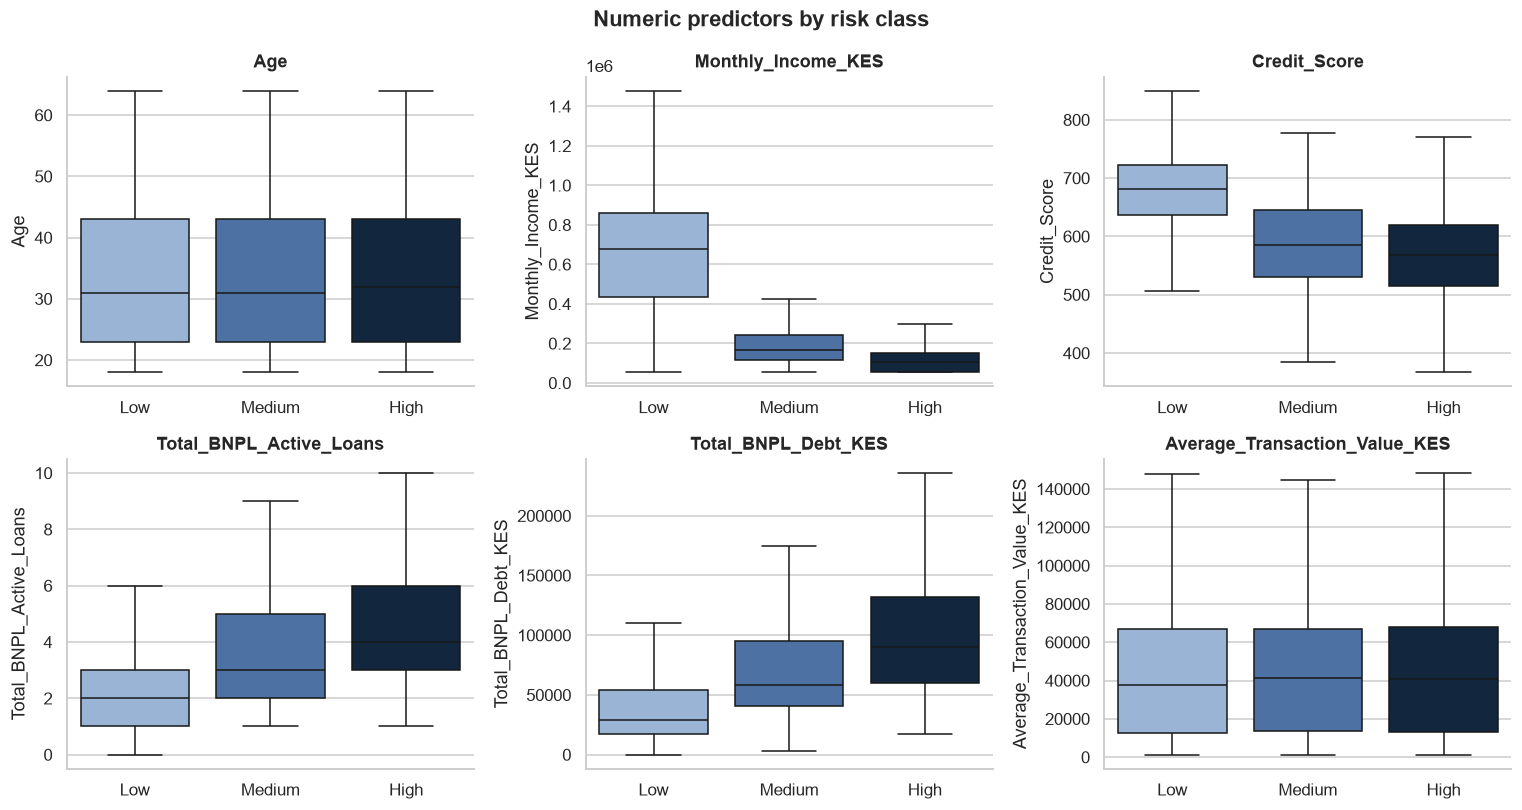

Default_Risk,Low,Medium,High
Median by class (money in KES),,,
Age,31.000,31.000,32.000
Monthly_Income_KES,"678,426.290","164,597.690","105,957.770"
Credit_Score,681.000,584.500,568.000
Total_BNPL_Active_Loans,2.000,3.000,4.000
Total_BNPL_Debt_KES,"29,355.140","58,580.390","90,403.440"
Average_Transaction_Value_KES,"37,668.100","41,110.185","40,785.460"


In [15]:
# Compare numerical predictors across default risk categories using boxplots and medians

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.flat, NUM_COLS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, order=CLASS_ORDER,
                hue_order=CLASS_ORDER, palette=RISK_COLORS,
                showfliers=False, legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
plt.suptitle("Numeric predictors by risk class", fontweight="bold")
plt.tight_layout(); plt.savefig("figures/04_numeric_by_risk.png"); plt.show()

display(df.groupby(TARGET)[NUM_COLS].median().reindex(CLASS_ORDER).T.rename_axis("Median by class (money in KES)"))

**Interpretation:**
- Higher default risk is associated with lower monthly income and credit scores, alongside higher BNPL debt and more active loans.
- Age and average transaction value show minimal differences across risk categories.
- Therefore, income, credit score, debt, and active loans appear to be important potential predictors of default risk.

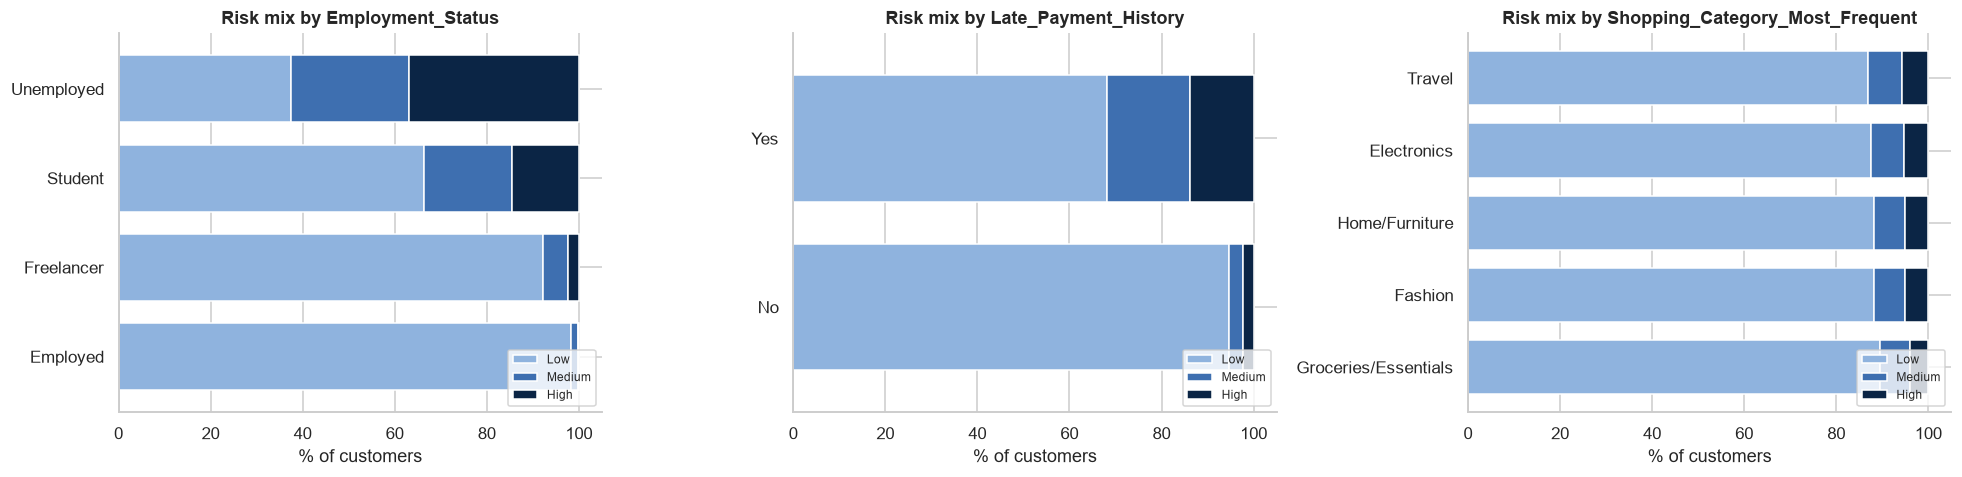

In [16]:
# Compare default risk percentages across customer categories to identify potential risk patterns

fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(6 * len(CAT_COLS), 4.5))
for ax, col in zip(np.atleast_1d(axes), CAT_COLS):
    ct = pd.crosstab(df[col].astype(str), df[TARGET], normalize="index")[CLASS_ORDER] * 100
    ct = ct.sort_values("High")
    ct.plot(kind="barh", stacked=True, color=[RISK_COLORS[c] for c in CLASS_ORDER], ax=ax, width=.75)
    ax.set_title(f"Risk mix by {col}"); ax.set_xlabel("% of customers"); ax.set_ylabel("")
    ax.legend(title="", loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig("figures/05_risk_mix_by_category.png"); plt.show()

**Interpretation:**
- Default risk varies across employment status, late payment history, and shopping categories.
- Customers with previous late payments and those who are unemployed appear more likely to be classified as High Risk.
- These factors may be useful predictors of default risk, subject to confirmation using the actual dataset results.

### Statistical Analysis of Relationships Between Variables
This analysis uses statistical tests to determine whether customer characteristics are significantly associated with default risk and identify potential predictors for the machine learning model.


In [17]:
# ANOVA and Chi-square tests to assess relationships with default risk.

rows = []
for col in NUM_COLS:
    groups = [g.dropna() for _, g in df.groupby(TARGET)[col]]
    f, p = stats.f_oneway(*groups)
    rows.append({"feature": col, "test": "ANOVA", "statistic": f, "p_value": p})

def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

for col in CAT_COLS:
    ct = pd.crosstab(df[col], df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rows.append({"feature": col, "test": "Chi-square", "statistic": chi2, "p_value": p})

assoc = pd.DataFrame(rows).sort_values("statistic", ascending=False)
assoc["significant_5%"] = assoc["p_value"] < 0.05
assoc

,feature,test,statistic,p_value,significant_5%
6,Employment_Status,Chi-square,"2,904.151",0.000,True
1,Monthly_Income_KES,ANOVA,"1,284.684",0.000,True
7,Late_Payment_History,Chi-square,"1,242.268",0.000,True
2,Credit_Score,ANOVA,"1,021.399",0.000,True
4,Total_BNPL_Debt_KES,ANOVA,917.278,0.000,True
3,Total_BNPL_Active_Loans,ANOVA,743.030,0.000,True
8,Shopping_Category_Most_Frequent,Chi-square,3.401,0.907,False
5,Average_Transaction_Value_KES,ANOVA,1.473,0.229,False
0,Age,ANOVA,0.086,0.918,False


**Interpretation:**
- Six variables show statistically significant relationships with default risk (p < 0.05): employment status, income, late payment history, credit score, BNPL debt, and active loans. Age, transaction value, and shopping category show no significant relationship.
- The six significant variables are potential predictors of default risk.

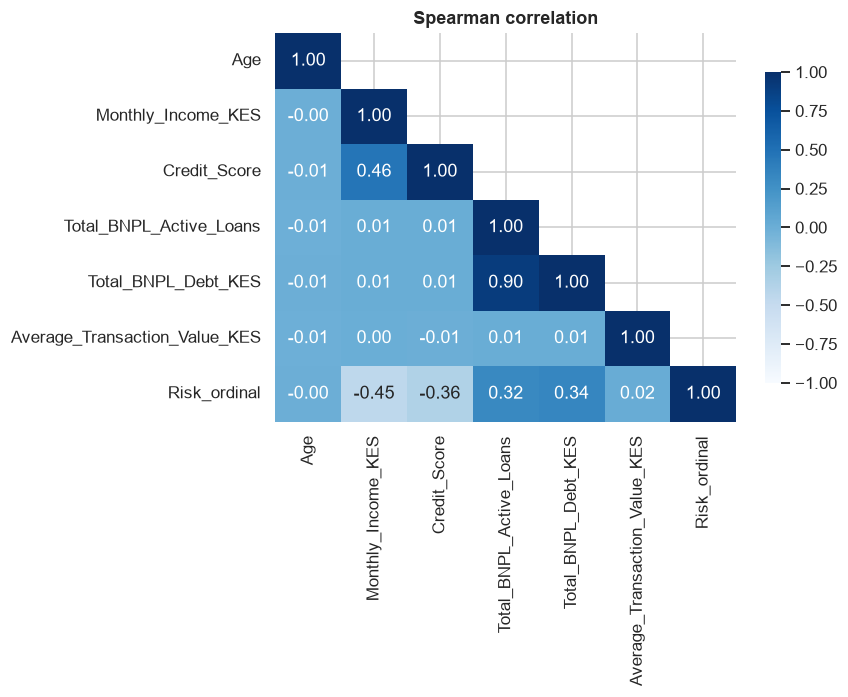

In [18]:
# Analyse correlations between numerical predictors and default risk using Spearman's correlation.

corr_df = df[NUM_COLS].copy()
corr_df["Risk_ordinal"] = df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})
corr = corr_df.corr(method="spearman")

plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cbar_kws={"shrink": .8})
plt.title("Spearman correlation")
plt.tight_layout(); plt.savefig("figures/06_correlation.png"); plt.show()

## 2.9 EDA Summary and Modelling Considerations
- **Key Predictors:** Income, credit score, BNPL debt, active loans, employment status, and late payment history show significant associations with default risk.
- **Customer Segmentation:** Higher-risk customers generally have lower incomes, lower credit scores, and higher debt.
- **Multicollinearity:** Predictor correlations above |r| > 0.8 require further review.
- **Leakage and Bias:** Late payment history requires timing checks, while age, employment status, and dataset representativeness raise fairness concerns.
- **Modelling Readiness:** The dataset is suitable for initial modelling, but missing values and class imbalance (88% Low Risk) must be addressed.

**Conclusion:** Appropriate preprocessing, leakage prevention, and imbalance handling are essential for developing a reliable prediction model.

# 3. Data Preparation
## 3.1 Data Cleaning and Duplicate Handling

This stage prepares the dataset for modelling by standardising values, correcting data types, handling invalid entries, and identifying duplicate records.

In [19]:
# Clean and standardise data, identify duplicates, and log removed records.

YES = {"yes", "y", "true", "1"}
NO = {"no", "n", "false", "0"}

def clean_data(frame: pd.DataFrame) -> pd.DataFrame:
    # Standardise values and flag invalid entries
    out = frame.copy()
    out.columns = out.columns.str.strip()

    for col in out.select_dtypes(exclude="number"):
        out[col] = out[col].astype("string").str.strip().replace("", pd.NA)

    for col in ["Employment_Status", "Shopping_Category_Most_Frequent", TARGET]:
        if col in out:
            out[col] = out[col].str.title()

    if "Late_Payment_History" in out:
        lp = out["Late_Payment_History"].astype("string").str.lower()
        out["Late_Payment_History"] = lp.map(
            {**dict.fromkeys(YES, 1), **dict.fromkeys(NO, 0)}
        )

    for col in NUM_COLS:
        if col in out:
            out[col] = pd.to_numeric(out[col], errors="coerce")

    for col, (low, high) in {"Age": (18, 100), "Credit_Score": (300, 900)}.items():
        if col in out:
            out.loc[~out[col].between(low, high), col] = np.nan

    for col in ["Monthly_Income_KES", "Total_BNPL_Debt_KES",
                "Average_Transaction_Value_KES", "Total_BNPL_Active_Loans"]:
        if col in out:
            out.loc[out[col] < 0, col] = np.nan

    return out


# Check duplicates and record removals
cleaning_log = []

def log_removal(frame, mask, reason):
    for rid in frame.loc[mask, ID_COL] if ID_COL in frame else frame.index[mask]:
        cleaning_log.append({"record": rid, "action": "removed", "reason": reason})
    return frame.loc[~mask].copy()


before = len(df)
df = clean_data(df)
profile_cols = [c for c in df if c != ID_COL]
predictor_cols = [c for c in profile_cols if c != TARGET]

dup_summary = {
    "Exact duplicate rows": int(df.duplicated().sum()),
    "Repeated Customer_ID": int(df[ID_COL].duplicated().sum()) if ID_COL in df else 0,
    "Repeated profile": int(df.duplicated(subset=profile_cols).sum()),
    "Conflicting labels": int(
        (df.groupby(predictor_cols, dropna=False)[TARGET].transform("nunique") > 1).sum())
}
display(pd.Series(dup_summary, name="records").to_frame())

df = log_removal(df, df.duplicated(), "exact duplicate row")

if ID_COL in df:
    df = log_removal(df, df[ID_COL].duplicated(), "repeated Customer_ID")

df = log_removal(df, df.duplicated(subset=profile_cols), "repeated profile")

conflict = df.groupby(predictor_cols, dropna=False)[TARGET].transform("nunique") > 1
df = log_removal(df, conflict, "conflicting risk labels")
df = log_removal(df, ~df[TARGET].isin(CLASS_ORDER), "invalid target")
df = df.reset_index(drop=True)

print(f"Rows: {before:,} -> {len(df):,} (removed {before - len(df):,})")
print("No duplicates found; nothing removed." if not cleaning_log else f"{len(cleaning_log)} removals logged.")

,records
Exact duplicate rows,0
Repeated Customer_ID,0
Repeated profile,0
Conflicting labels,0


Rows: 10,000 -> 10,000 (removed 0)
No duplicates found; nothing removed.


**Interpretation:**
- No duplicate records, repeated customer IDs, or conflicting risk labels were identified.
- All 10,000 records were retained, indicating good data consistency and no need for duplicate removal.

# 3.2 Splitting the Dataset for Model Training and Testing

The dataset is divided into 80% training data (8,000 records) and 20% testing data (2,000 records). Stratified sampling maintains similar proportions of default risk categories in both sets.

The split is performed before handling missing values to prevent data leakage.



In [20]:
# Select model features and perform an 80/20 stratified train-test split
FEATURES_FULL = [c for c in NUM_COLS + ["Late_Payment_History"] +
                 [c for c in CAT_COLS if c != "Late_Payment_History"] if c in df]
print("Excluded from modelling:", [c for c in df.columns if c not in FEATURES_FULL + [TARGET]])
print("Model inputs           :", FEATURES_FULL)

train_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=df[TARGET],
                                       random_state=RANDOM_STATE)
split_check = pd.DataFrame({
    "train_%": df.loc[train_idx, TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100,
    "test_%": df.loc[test_idx, TARGET].value_counts(normalize=True).reindex(CLASS_ORDER) * 100})
print(f"Train: {len(train_idx):,}  Test: {len(test_idx):,}")
split_check.round(2)

Excluded from modelling: ['Customer_ID']
Model inputs           : ['Age', 'Monthly_Income_KES', 'Credit_Score', 'Total_BNPL_Active_Loans', 'Total_BNPL_Debt_KES', 'Average_Transaction_Value_KES', 'Late_Payment_History', 'Employment_Status', 'Shopping_Category_Most_Frequent']
Train: 8,000  Test: 2,000


,train_%,test_%
Default_Risk,,
Low,88.010,88.000
Medium,6.780,6.800
High,5.210,5.200


**Interpretation:**
- Nine relevant features were selected for modelling, excluding Customer_ID as it is only an identifier.
- The dataset was split into 80% training (8,000 records) and 20% testing (2,000 records).
- Stratified sampling preserved nearly identical default risk proportions in both sets, ensuring a representative split despite class imbalance.

## 3.3 Correct Missing Values
Missing values are filled using employment-group medians calculated from the training data to prevent data leakage.

**-Median imputation:** Reduces the influence of outliers.

**-Fallback:** Uses the overall training median where group values are unavailable.

**- Missing tests:** No significant relationship with default risk was found (p > 0.05).

**- Pipeline safeguard:** SimpleImputer handles any remaining missing values.

In [21]:
# Fill missing values using training-set medians and log changes

IMPUTE_COLS = [c for c in NUM_COLS if df[c].isna().any()]
GROUP_COL = "Employment_Status"
missing_before = df[IMPUTE_COLS].isna().sum()

train_part = df.loc[train_idx]
GROUP_MEDIANS = {c: train_part.groupby(GROUP_COL)[c].median().to_dict() for c in IMPUTE_COLS}
OVERALL_MEDIANS = {c: float(train_part[c].median()) for c in IMPUTE_COLS}

def impute_missing(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    for c in IMPUTE_COLS:
        fill = out[GROUP_COL].map(GROUP_MEDIANS[c]).fillna(OVERALL_MEDIANS[c])
        out[c] = out[c].fillna(fill)
    return out

imputed_mask = df[IMPUTE_COLS].isna()
df = impute_missing(df)

for c in IMPUTE_COLS:
    for rid in df.loc[imputed_mask[c], ID_COL]:
        cleaning_log.append({"record": rid, "action": f"imputed {c}",
                             "reason": "missing; filled with employment-group training median"})

display(pd.DataFrame(GROUP_MEDIANS).rename_axis("Training medians by " + GROUP_COL))
display(pd.DataFrame({"missing_before": missing_before,
                      "missing_after": df[IMPUTE_COLS].isna().sum()}))
assert df[NUM_COLS].isna().sum().sum() == 0, "Numeric gaps remain"

pd.DataFrame(cleaning_log).to_csv("reports/data_cleaning_log.csv", index=False)
print(f"Cleaning log: {len(cleaning_log):,} entries saved to reports/data_cleaning_log.csv")

,Monthly_Income_KES,Credit_Score
Training medians by Employment_Status,,
Employed,"763,428.475",699.000
Freelancer,"585,078.680",646.000
Student,"160,998.660",598.000
Unemployed,"113,918.945",544.500


,missing_before,missing_after
Monthly_Income_KES,305,0
Credit_Score,298,0


Cleaning log: 603 entries saved to reports/data_cleaning_log.csv


**Interpretation:**
- Income and credit scores vary significantly across employment groups, with employed customers having the highest medians and unemployed customers the lowest.
-  All 603 missing values (305 income and 298 credit scores) were successfully filled using training-based medians.
-  No missing numeric values remain, and all changes were recorded in the cleaning log.